In [1]:
import numpy as np
import matplotlib.pyplot as plt

import camb
from camb import model
print("CAMB version:", camb.__version__)

CAMB version: 2.0.4


In [2]:
class_meta = {
    "h": 0.674,
    "omega_b": 0.0224,
    "omega_cdm": 0.120,
    "Omega_k": 0.0,
    "N_ur": 2.0308,
    "N_ncdm": 1,
    "m_ncdm_eV": 0.06,
    "T_ncdm": 0.71611,
    "tau_reio": 0.054,
    "A_s": 2.10e-9,
    "n_s": 0.965,
    "k_pivot_Mpc": 0.05,
    "z_pk": 0.0,
    "nonlinear": "none",
    "matter_component": "total matter",
    "transfer_column": "d_m",
    "k_input_units": "h/Mpc",
    "P_input_units": "(Mpc/h)^3",
    "transfer_normalization": "initial curvature R = 1",
    "evolution_gauge": "synchronous",
    "matter_source_in_current_gauge": False,
    "matter_density_convention": "gauge-invariant / comoving density",
    "transfer_normalization": "initial curvature R = 1",
    "matter_component": "total matter",    
    "CLASS_version": "3.4.0",
    "CLASS_revision": "64bbab707faf4de4779a9e04edd180fef18d98fa", 
}

CLASS evolves scalar perturbations in synchronous gauge (the default, since gauge is not explicitly specified). For the total-matter source, the default matter_source_in_current_gauge = no is also retained, so the delta_m source used for the matter output is expressed in the gauge-invariant/comoving-density convention rather than as the raw synchronous-gauge density.

In [3]:
pk = np.loadtxt("../outputs/class/base_pk.dat")
pk_cb = np.loadtxt("../outputs/class/base_pk_cb.dat")
tk = np.loadtxt("../outputs/class/base_tk.dat")

kh_pk, Ph = pk.T
kh_cb, Pcb_h = pk_cb.T

kh_tk = tk[:, 0]
Tm = tk[:, 6]       # d_m
d_tot = tk[:, 7]

assert np.allclose(kh_pk, kh_tk)
assert np.allclose(kh_pk, kh_cb)

h = class_meta["h"]
A_s = class_meta["A_s"]
n_s = class_meta["n_s"]
k_pivot = class_meta["k_pivot_Mpc"]

k = h * kh_pk              # Mpc^-1
P_class = Ph / h**3        # Mpc^3

print(f"N_k = {len(k)}")
print(f"k_h range = [{kh_pk.min():.4e}, {kh_pk.max():.4e}] h/Mpc")
print(f"k range   = [{k.min():.4e}, {k.max():.4e}] 1/Mpc")
print(f"same pk/tk grid: {np.array_equal(kh_pk, kh_tk)}")
print(f"same pk/pk_cb grid: {np.array_equal(kh_pk, kh_cb)}")

N_k = 610
k_h range = [1.0485e-05, 6.6937e+00] h/Mpc
k range   = [7.0669e-06, 4.5115e+00] 1/Mpc
same pk/tk grid: True
same pk/pk_cb grid: True


# Matter spectrum CLASS (5a)

In [4]:
pk = np.loadtxt("../outputs/class/base_pk.dat")
tk = np.loadtxt("../outputs/class/base_tk.dat")

kh = pk[:, 0]
P_class_h = pk[:, 1]

kh_tk = tk[:, 0]
T_m = tk[:, 6]  # d_m

assert np.allclose(kh, kh_tk)

# Convert CLASS tabulated units
k = h * kh                   # Mpc^-1
P_class = P_class_h / h**3   # Mpc^3

# Primordial curvature power per logarithmic interval
Delta_R2 = A_s * (k / k_pivot)**(n_s - 1.0)

# Matter power reconstructed from the density transfer
P_rec = 2.0 * np.pi**2 / k**3 * Delta_R2 * T_m**2

residual = P_rec / P_class - 1.0

print("CLASS matter-spectrum reconstruction")
print("====================================")
print(f"N_k                         = {len(k)}")
print(f"max |P_rec/P_CLASS - 1|     = {np.max(np.abs(residual)):.3e}")
print(f"mean residual               = {np.mean(residual):+.3e}")
print(f"rms residual                = {np.sqrt(np.mean(residual**2)):.3e}")

CLASS matter-spectrum reconstruction
N_k                         = 610
max |P_rec/P_CLASS - 1|     = 2.137e-12
mean residual               = -9.920e-15
rms residual                = 4.863e-13


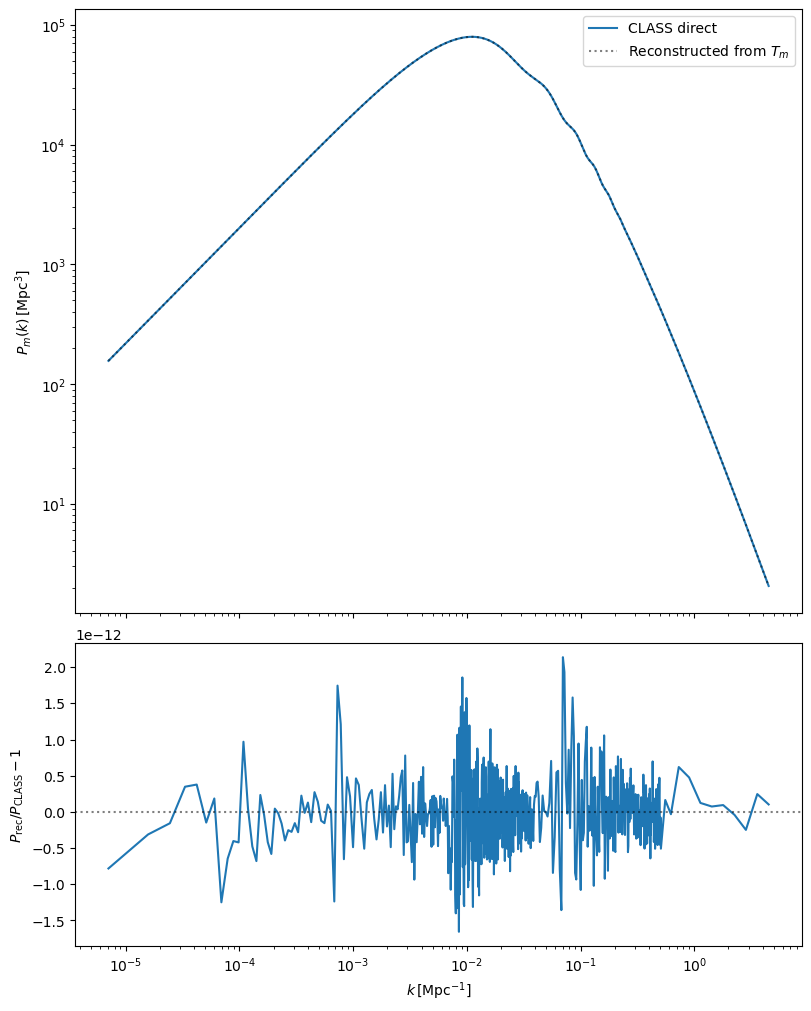

In [5]:
fig, ax = plt.subplots(nrows=2, figsize=(8, 10), sharex=True, 
                       gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")

# ------------------------------------------------------------
# Matter power spectrum
# ------------------------------------------------------------

ax[0].loglog(k, P_class, label="CLASS direct")
ax[0].loglog(k, P_rec, c="k", ls=":", alpha=0.5, label="Reconstructed from $T_m$")

ax[0].set_ylabel(r"$P_m(k)\,[\mathrm{Mpc}^3]$")
ax[0].legend()

# ------------------------------------------------------------
# Reconstruction residual
# ------------------------------------------------------------

ax[1].semilogx(k, residual)

ax[1].axhline(0.0, color="k", ls=":", alpha=0.5)
ax[1].set_xlabel(r"$k\,[\mathrm{Mpc}^{-1}]$")
ax[1].set_ylabel(r"$P_{\rm rec}/P_{\rm CLASS}-1$")

plt.savefig("../outputs/figures/05_CLASS_spectra.png", dpi=200)
plt.show()

We indeed check that the recovered spectra from CLASS follows the predicted prescription

\begin{equation}
P_m^\mathrm{rec}(k,z)=\frac{2\pi^2}{k^3}A_s\left(\frac{k}{k_*}\right)^{n_s-1}T_m^2(k,z)
\end{equation}

with $T_m=\delta_m/\mathcal{R}$, with the tabulated $k_h$ in $[h^{-1}\mathrm{Mpc}]$, converted as $k=hk_h$, and $P_h$ in $[h^{-3}\mathrm{Mpc}^3]$ and conversion $P=h^3P_h$. The fractional residual is of order $10^{-12}$ for its relative error, and therefore in agreement with the prediction.

In [6]:
# Checking that d_tot is not the desired quantity for T_m (column 7)
# and we want the d_m instead (column 6).
T_tot = tk[:, 7] # d_tot
P_rec_tot = 2.0 * np.pi**2 / k**3 * Delta_R2 * T_tot**2

print("max residual using d_tot instead of d_m:", np.max(np.abs(P_rec_tot / P_class - 1.0)))

max residual using d_tot instead of d_m: 0.000511622038129822


# Indentity and convergence tests (5b)

To test the convergence behavior of CLASS, we use a `tight.pre` additional parameter file that provides a higher resolution calculation based on the previous `base` run. The `tight.pre` parameters are as follows:

`k_step_sub` = 0.015

`k_step_super` = 0.0001

`k_step_super_reduction` = 0.1

`l_max_ur` = 150

`l_max_ncdm` = 50

`tol_perturbations_integration` = 1.e-6

`perturbations_sampling_stepsize` = 0.01

`ncdm_fluid_approximation` = 3

`ncdm_fluid_trigger_tau_over_tau_k` = 51.

`tol_ncdm_synchronous` = 1.e-10

`tol_ncdm` = 1.e-5

And we perform a series of runs that degrade the quality of each of the following parameters, to test their influence in the converged result:

| run | varied quantity | configuration |
|---|---|---|
| `base` | default | previous run |
| `tight` | reference | `class_base.ini + tight.pre` |
| `ode` | tolerance ODE | `tight`, but `tol_perturb_integration` = 1e-5 |
| `ktime` | temporal sampling | `tight`, but `perturb_sampling_stepsize` = 0.05 |
| `kk` | $k$ sampling | `tight`, but `k_step_sub` = 0.05 |
| `hierarchy` | hierarchy depth | `tight`, but `l_max_ncdm` = 25 |
| `switch` | approximation switch | `tight`, but `ncdm_fluid_trigger_tau_over_tau_k` = 25 |
| `momentum` | massive neutrino quadrature | `tight`, but `tol_ncdm` = 1.e-3 |

In [14]:
runs = [
    "base",
    "ode",
    "ktime",
    "kk",
    "hierarchy",
    "switch",
    "momentum",
]

def loadPk(prefix):
    data = np.loadtxt(f"../outputs/class/{prefix}_pk.dat")
    return data[:, 0], data[:, 1]


def logInterp(k_new, k, P):
    """
    Interpolate a positive power spectrum in log(k)-log(P).
    """
    return np.exp(np.interp(np.log(k_new), np.log(k), np.log(P)))

def powerResidual(prefix, kmax=5.0):
    kh, P = loadPk(prefix)

    overlap = (kh >= kh_tight.min()) & (kh <= kh_tight.max()) & (kh <= kmax)
    kh = kh[overlap]
    P = P[overlap]

    P_ref = logInterp(kh, kh_tight, P_tight)
    residual = P / P_ref - 1.0

    return kh, residual

In [ ]:
fig, ax = plt.subplots(ncols=2, figsize=(12, 6), sharex=True, layout="constrained")

general_runs = ["base", "ode", "ktime", "kk"]
ncdm_runs = ["hierarchy", "switch", "momentum"]

for name in general_runs:
    k, res = powerResidual(name)
    ax[0].semilogx(k, res, label=name)

for name in ncdm_runs:
    k, res = powerResidual(name)
    ax[1].semilogx(k, res, label=name)

for a in ax:
    a.axhline(0.0, color="k", ls="--", lw=0.8)
    a.set_xlabel(r"$k\,[h\,\mathrm{Mpc}^{-1}]$")
    a.legend()

a[0].set_ylabel(r"$P/P_{\rm tight}-1$")

plt.show()

In [ ]:
def residualSummary(prefix):
    k, residual = powerResidual(prefix)
    abs_res = np.abs(residual)
    imax = np.argmax(abs_res)

    return {
        "run": prefix,
        "max_abs": abs_res[imax],
        "k_at_max": k[imax],
        "rms": np.sqrt(np.mean(residual**2)),
        "p95_abs": np.percentile(abs_res, 95),
    }


print("run          max|dP/P|       k(max)       rms          p95")
print("-" * 72)

for name in runs:
    s = residualSummary(name)
    print(
        f"{name:10s} "
        f"{s['max_abs']:12.3e}   "
        f"{s['k_at_max']:8.3f}   "
        f"{s['rms']:10.3e}   "
        f"{s['p95_abs']:10.3e}"
    )

In [ ]:
k_ranges = {
    "low":  (1e-4, 1e-2),
    "mid1": (1e-2, 1e-1),
    "mid2": (1e-1, 1.0),
    "high": (1.0, 5.0),
}

for name in runs:
    k, residual = powerResidual(name)
    print(f"\n{name}")
    for label, (kmin, kmax) in k_ranges.items():
        mask = (k >= kmin) & (k < kmax)

        if np.any(mask):
            print(
                f"  {label:5s}: "
                f"max = "
                f"{np.max(np.abs(residual[mask])):.3e}, "
                f"rms = "
                f"{np.sqrt(np.mean(residual[mask]**2)):.3e}"
            )

# CLASS x CAMB comparision (5c)

In [7]:
camb_meta = {
    "H0": 100.0 * class_meta["h"],
    "ombh2": class_meta["omega_b"],
    "omch2": class_meta["omega_cdm"],
    "omk": class_meta["Omega_k"],
    "mnu": class_meta["m_ncdm_eV"],
    "num_massive_neutrinos": class_meta["N_ncdm"],
    "neutrino_hierarchy": "degenerate",

    # CLASS N_ur + one thermal ncdm species correspond
    # to the standard total relativistic normalization.
    "nnu": 3.044,
    "tau": class_meta["tau_reio"],
}

In [8]:
pars = camb.CAMBparams()
pars.set_cosmology(**camb_meta)

pars.InitPower.set_params(As=class_meta["A_s"], ns=class_meta["n_s"], pivot_scalar=class_meta["k_pivot_Mpc"])
pars.NonLinear = model.NonLinear_none

pars.set_accuracy(AccuracyBoost=2.0, lAccuracyBoost=2.0, lSampleBoost=2.0)
pars.set_matter_power(redshifts=[class_meta["z_pk"]], kmax=6.0, nonlinear=False, accurate_massive_neutrino_transfers=True)

print(pars)
print("CAMB effective N_eff =", pars.N_eff)

class: <CAMBparams>
 WantCls = True
 WantTransfer = True
 WantScalars = True
 WantTensors = False
 WantVectors = False
 WantDerivedParameters = True
 Want_cl_2D_array = True
 Want_CMB = True
 Want_CMB_lensing = True
 DoLensing = True
 NonLinear = NonLinear_none
 Transfer: <TransferParams>
   high_precision = True
   accurate_massive_neutrinos = True
   kmax = 6.0
   k_per_logint = 0
   PK_num_redshifts = 1
   PK_redshifts = [0.0]
 want_zstar = False
 want_zdrag = False
 min_l = 2
 max_l = 2500
 max_l_tensor = 600
 lens_output_margin = 200
 max_eta_k = 6250.0
 max_eta_k_tensor = 1200.0
 ombh2 = 0.0224
 omch2 = 0.12
 omk = 0.0
 omnuh2 = 0.0006448993754203254
 H0 = 67.4
 TCMB = 2.7255
 YHe = 0.24566901942417868
 num_nu_massless = 2.0293333333333337
 num_nu_massive = 1
 nu_mass_eigenstates = 1
 share_delta_neff = False
 nu_mass_degeneracies = [1.0146666666666666]
 nu_mass_fractions = [1.0]
 nu_mass_numbers = [1]
 InitPower: <InitialPowerLaw>
   tensor_parameterization = tensor_param_rpivot

In [9]:
print("CLASS -> CAMB parameter mapping")
print("--------------------------------")
print(f"H0      = {100.0 * class_meta['h']:.3f} km/s/Mpc")
print(f"ombh2   = {class_meta['omega_b']:.5f}")
print(f"omch2   = {class_meta['omega_cdm']:.5f}")
print(f"omk     = {class_meta['Omega_k']:.5f}")
print(f"mnu     = {class_meta['m_ncdm_eV']:.3f} eV")
print(f"N_mass  = {class_meta['N_ncdm']}")
print(f"N_eff   = 3.044")
print(f"tau     = {class_meta['tau_reio']:.3f}")
print(f"As      = {class_meta['A_s']:.3e}")
print(f"ns      = {class_meta['n_s']:.3f}")
print(f"k_pivot = {class_meta['k_pivot_Mpc']:.3f} 1/Mpc")

CLASS -> CAMB parameter mapping
--------------------------------
H0      = 67.400 km/s/Mpc
ombh2   = 0.02240
omch2   = 0.12000
omk     = 0.00000
mnu     = 0.060 eV
N_mass  = 1
N_eff   = 3.044
tau     = 0.054
As      = 2.100e-09
ns      = 0.965
k_pivot = 0.050 1/Mpc


In [10]:
# Run CAMB
results_camb = camb.get_results(pars)

# Total-matter linear power interpolator
PK_camb = results_camb.get_matter_power_interpolator(nonlinear=False, var1="delta_tot", var2="delta_tot", 
                                                     hubble_units=True, k_hunit=True)

In [11]:
class_data = np.loadtxt("../outputs/class/tight_pk.dat")
kh_class = class_data[:, 0]   # h/Mpc

P_class = class_data[:, 1]    # (Mpc/h)^3
P_camb = PK_camb.P(class_meta["z_pk"], kh_class)
residual_camb = P_camb / P_class - 1.0

mask = (kh_class >= 1.0e-4) & (kh_class <= 5.0)

k_cmp = kh_class[mask]
P_class_cmp = P_class[mask]
P_camb_cmp = P_camb[mask]
res_cmp = residual_camb[mask]

imax = np.argmax(np.abs(res_cmp))

print("CLASS tight vs CAMB")
print("===================")
print(f"N_k              = {len(k_cmp)}")
print(f"max |Delta P/P|  = {np.max(np.abs(res_cmp)):.3e}")
print(f"k at max         = {k_cmp[imax]:.4e} h/Mpc")
print(f"mean residual    = {np.mean(res_cmp):+.3e}")
print(f"RMS residual     = {np.sqrt(np.mean(res_cmp**2)):.3e}")
print(f"P95 |residual|   = {np.percentile(np.abs(res_cmp), 95):.3e}")

CLASS tight vs CAMB
N_k              = 6325
max |Delta P/P|  = 8.500e-04
k at max         = 9.6498e-02 h/Mpc
mean residual    = -5.254e-05
RMS residual     = 8.470e-05
P95 |residual|   = 1.269e-04


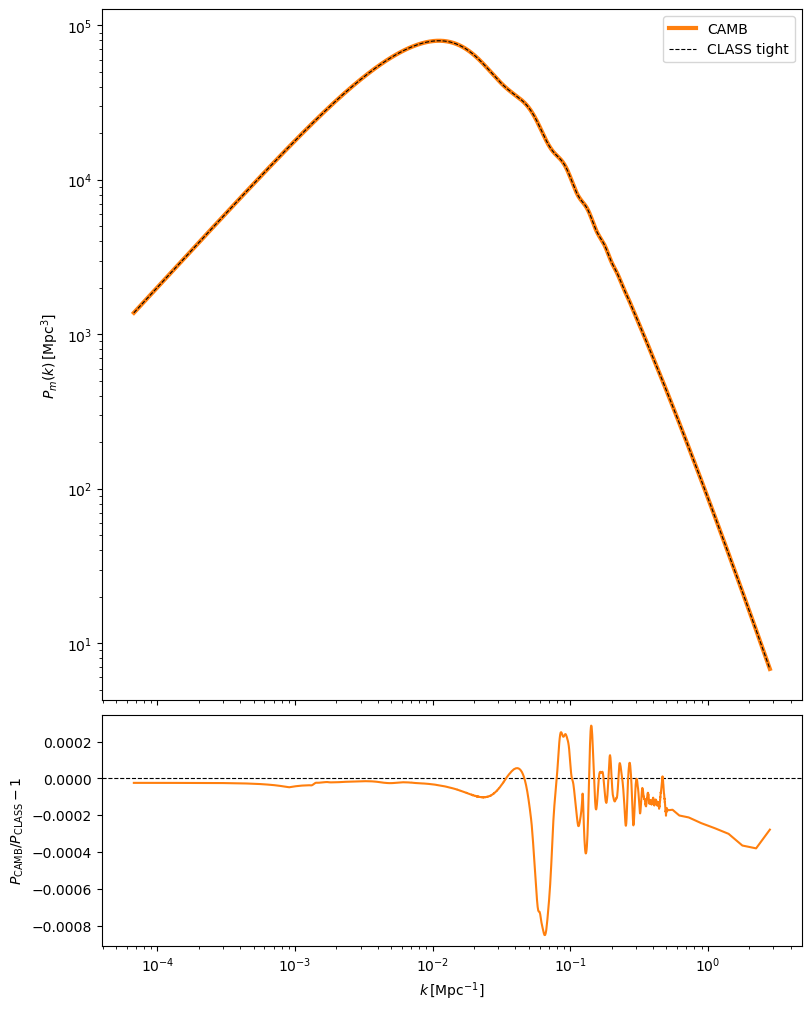

In [13]:
fig, ax = plt.subplots(nrows=2, figsize=(8, 10), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1]}, layout="constrained")

ax[0].loglog(h*k_cmp, P_camb_cmp/h**3, c="C1", lw=3, label="CAMB")
ax[0].loglog(h*k_cmp, P_class_cmp/h**3, c="k", ls="--", lw=0.8, label="CLASS tight")

ax[0].set_ylabel(r"$P_m(k)\,[\mathrm{Mpc}^3]$")
ax[0].legend()

ax[1].axhline(0.0, c="k", ls="--", lw=0.8)
ax[1].semilogx(h*k_cmp, res_cmp, c="C1")
ax[1].set_xlabel(r"$k\,[\mathrm{Mpc}^{-1}]$")
ax[1].set_ylabel(r"$P_{\rm CAMB}/P_{\rm CLASS}-1$")

plt.savefig("../outputs/figures/05_CLASS_CAMB.png", dpi=200)
plt.show()

From this test, we check that both CLASS and CAMB, over similar initial conditions, generate similar results within a relative diference of $\lesssim0.1\%$ (with bigger systematic differences only at higher $k$ frequencies).